# What does Perrault-Joncas & Meila (PJM) say about the magnitude of the drift?

PJM (2011) estimates a vector field $R=\tfrac12(H_{aa}-H_{ss})Y$ from the directed kernel, in the coordinates $Y$ of an embedding. Ours estimates the Randers drift $V$, the cometric $\Gamma$ and the strength $\|c\|^2_{g_{BL}}$. All the experiments so far show the same direction for both. This notebook asks what each says about the *magnitude*, with three questions:

1. **Relative magnitude.** Does the norm of the estimate follow the spatial variation of the true strength?
2. **Calibration.** Is the norm of the estimate equal to the true norm, without a constant to fit?
3. **Intrinsic strength.** Is the strength read from the estimate a property of the data, or of the coordinates of the embedding?

The ground truth is known in closed form on the Swiss roll, the Matsumoto surface and GlobCurrent (the true drift in the embedding is $C\,J c$, with $C$ the constant of the kernel moments and $J$ the Jacobian of the embedding). The same radius graphs, bandwidth and 2D Isomap embedding are used for both methods.

Two points on the algorithm as printed (arXiv:1406.0013, Algorithm 1). Step 13 is $R=(\Phi\Lambda-H_{aa}\Phi)/2$, with no division by the bandwidth: the identity $(H_{aa}-H_{ss})\psi_k=-2r_k$ of the paper (its eq. 22) is for the limit operators $(T-I)/\epsilon$. And it is the opposite sign of the one used here, $R=(H_{aa}-H_{ss})Y/2$: the paper is not consistent on the sign of $r\cdot\nabla\phi$ (its eq. 9 and eq. 12 differ), and the sign used here is the one of the kernel convention of its eq. 2 (the kernel is larger towards the drift), so that $R$ points along the true drift.

In [1]:
import warnings
from functools import partialmethod

warnings.filterwarnings("ignore")  # deprecation notice of torch.jit at import

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr
from tqdm import tqdm

from finsler_embedding.core.embeddings import isomap_embedding
from finsler_embedding.core.kernels import gaussian_kernel, randers_constants
from finsler_embedding.core.operators import randers_approximation
from finsler_embedding.experiments.baselines import perrault_joncas_meila
from finsler_embedding.experiments.finsler_mds_manifolds import DEFAULT_RADIUS
from finsler_embedding.experiments.legacy.evaluation import DATASETS, build_graph, evaluate_embedding, local_jacobian

tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)  # no progress bars for the distances of the graph

N = 2000
SEED = 0
SETTINGS = [("swiss_roll", 0.3), ("swiss_roll", 0.9), ("matsumoto", None), ("globcurrent", 0.5), ("globcurrent", 0.9)]
MULTS = (0.5, 0.7, 1.0)  # kernel bandwidth, as a fraction of the one of the other experiments
_, C, _ = randers_constants(2)

In [2]:
def prepare(dataset, beta):
    """Data, radius graph, bandwidth, 2D Isomap embedding and its Jacobian, for one setting."""
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    data = DATASETS[dataset](N) if beta is None else DATASETS[dataset](N, beta)
    _, edges, dst, eps = build_graph(data["X_graph"], data["F"], "radius", 10, 1.0, 0.5, 2, 3.0, DEFAULT_RADIUS[dataset], "cpu")
    Y = isomap_embedding(data["X_graph"].detach(), n_components=2, n_neighbors=10)
    J = local_jacobian(data["X_chart"].detach(), Y, data["P"])
    truth = data["truth"]
    strength = torch.einsum("ni,nij,nj->n", truth["c"], torch.linalg.inv(truth["g_bl_inv"]), truth["c"])
    return dict(data=data, edges=edges, dst=dst, eps=eps, Y=Y, J=J, truth=truth, strength=strength)


def estimate(s, mult=1.0, A=None):
    """Both estimators on one setting. ``A`` (2, 2) reparametrises the embedding: Y -> A Y (and J -> A J)."""
    Y, J = s["Y"], s["J"]
    if A is not None:
        Y, J = Y @ A.T, torch.einsum("ab,nbm->nam", A, J)
    h = mult * s["eps"]
    W, _, _ = gaussian_kernel(s["edges"], s["dst"], h, len(Y))
    result = randers_approximation(W, h, X_low=Y, m=2)
    R = torch.as_tensor(perrault_joncas_meila.vector_field(W.numpy(), Y.numpy()), dtype=torch.float32)
    ok = torch.isfinite(R).all(dim=1)  # undefined where the kernel is truncated and a node has no out-edge
    reference = C * torch.einsum("nlm,nm->nl", J, s["truth"]["c"])  # the true drift, in the coordinates of the embedding
    relerr = evaluate_embedding(result, Y, J, s["truth"], 2, {})["relerr_c_norm_all"]
    return dict(h=h, ok=ok, result=result, R=R, reference=reference, relerr=relerr)


states = {(d, b): prepare(d, b) for d, b in SETTINGS}
{f"{d} {b}": f"bandwidth {s['eps']:.3g}" for (d, b), s in states.items()}

{'swiss_roll 0.3': 'bandwidth 0.462',
 'swiss_roll 0.9': 'bandwidth 0.16',
 'matsumoto None': 'bandwidth 0.22',
 'globcurrent 0.5': 'bandwidth 53.2',
 'globcurrent 0.9': 'bandwidth 52.8'}

## 1. Relative magnitude

Spearman correlation, over the nodes, between the norm of the estimate and the true one: ours $\|V\|$ and $\|c\|^2_{g_{BL}}$ (the strength, which uses the cometric), PJM $\|R\|$. `spread` is the ratio between the 90% and the 10% quantiles of the true strength: a correlation means nothing when the strength is constant (Swiss roll, spread 1.0).

In [3]:
def spearman(a, b):
    return spearmanr(a.numpy(), b.numpy()).statistic


rows = {}
for (d, b), s in states.items():
    e = estimate(s)
    ok, reference = e["ok"], e["reference"]
    rows[f"{d} {b}"] = {
        "spread of the true strength": float(s["strength"].quantile(0.9) / s["strength"].quantile(0.1)),
        "ours |V|": spearman(e["result"].drift.norm(dim=1), reference.norm(dim=1)),
        "ours ||c||^2": spearman(e["result"].drift_norm_squared, s["strength"]),
        "PJM |R|": spearman(e["R"][ok].norm(dim=1), reference[ok].norm(dim=1)),
    }
pd.DataFrame(rows).T.round(2)

,spread of the true strength,ours |V|,ours ||c||^2,PJM |R|
swiss_roll 0.3,1.02,0.03,0.12,0.18
swiss_roll 0.9,1.01,-0.26,0.01,0.04
matsumoto None,4.39,0.78,0.87,0.79
globcurrent 0.5,73.46,0.96,0.96,0.95
globcurrent 0.9,47.07,0.96,0.97,0.95


## 2. Calibration

Median over the nodes of (norm of the estimate) / (true norm in the embedding, $\|C\,J c\|$), for three bandwidths of the kernel. A calibrated estimator gives 1. `PJM / h` is PJM divided by the bandwidth, and `2 PJM / h` also undoes the factor $\tfrac12$ of its formula. `PJM / h^2` is what the theory of the paper prescribes: its $\epsilon$ is $h^2$ here (our kernel is $\exp(-(d/h)^2)$, theirs $e^{-u}$ with $u=d^2/\epsilon$), and its eq. 22 holds after the division by $\epsilon$.

The two scalings differ because the generative models differ. In the model of the paper the asymmetric part of the kernel is $\tfrac r2(y-x)h_\epsilon$, so a step moves by about $\epsilon\,r$ on average. In a kernel built from a Randers distance the asymmetry has one more factor $|v|\sim h$, and a step moves by a multiple of $h$ (the constant $C$ is the first moment of the kernel, `randers_constants`). Dividing by $h$ is therefore the scale law of the moment-Randers analysis, not of PJM; dividing by $\epsilon$ is the one of PJM, and the table checks that it does not calibrate these kernels.

In [4]:
rows = []
for (d, b), s in states.items():
    for mult in MULTS:
        e = estimate(s, mult)
        ok, reference = e["ok"], e["reference"]
        ours = (e["result"].drift.norm(dim=1) / reference.norm(dim=1)).median().item()
        pjm = (e["R"][ok].norm(dim=1) / reference[ok].norm(dim=1)).median().item()
        rows.append({"setting": f"{d} {b}", "bandwidth h": e["h"], "ours": ours, "PJM": pjm, "PJM / h": pjm / e["h"], "2 PJM / h": 2 * pjm / e["h"], "PJM / h^2": pjm / e["h"] ** 2})
calibration = pd.DataFrame(rows).set_index(["setting", "bandwidth h"])
calibration.round(3)

ours     PJM  PJM / h  2 PJM / h  PJM / h^2
setting         bandwidth h                                              
swiss_roll 0.3  0.231103     1.137   0.140    0.605      1.210      2.617
                0.323544     1.050   0.178    0.552      1.103      1.705
                0.462206     1.001   0.242    0.523      1.046      1.132
swiss_roll 0.9  0.079783     0.971   0.041    0.515      1.031      6.458
                0.111696     0.896   0.052    0.462      0.924      4.138
                0.159566     0.803   0.066    0.414      0.828      2.594
matsumoto None  0.110249     1.111   0.066    0.598      1.197      5.427
                0.154349     1.027   0.084    0.546      1.092      3.538
                0.220498     0.978   0.115    0.522      1.045      2.369
globcurrent 0.5 26.597914    1.362  18.523    0.696      1.393      0.026
                37.237079    1.092  20.691    0.556      1.111      0.015
                53.195827    0.952  25.490    0.479      0.958      0.009
globcurrent 0.9 26.415359    1.343  18.198    0.689      1.378      0.026
                36.981503    1.086  20.490    0.554      1.108      0.015
                52.830719    0.948  25.320    0.479      0.959      0.009

In [5]:
print(f"ours:    from {calibration['ours'].min():.2f} to {calibration['ours'].max():.2f}")
print(f"PJM:     from {calibration['PJM'].min():.3f} to {calibration['PJM'].max():.1f}  (a factor {calibration['PJM'].max() / calibration['PJM'].min():.0f})")
print(f"PJM / h: from {calibration['PJM / h'].min():.2f} to {calibration['PJM / h'].max():.2f}")
print(f"2 PJM / h: from {calibration['2 PJM / h'].min():.2f} to {calibration['2 PJM / h'].max():.2f}")
print(f"PJM / h^2: from {calibration['PJM / h^2'].min():.3g} to {calibration['PJM / h^2'].max():.3g}  (a factor {calibration['PJM / h^2'].max() / calibration['PJM / h^2'].min():.0f})")

ours:    from 0.80 to 1.36
PJM:     from 0.041 to 25.5  (a factor 620)
PJM / h: from 0.41 to 0.70
2 PJM / h: from 0.83 to 1.39
PJM / h^2: from 0.00901 to 6.46  (a factor 717)


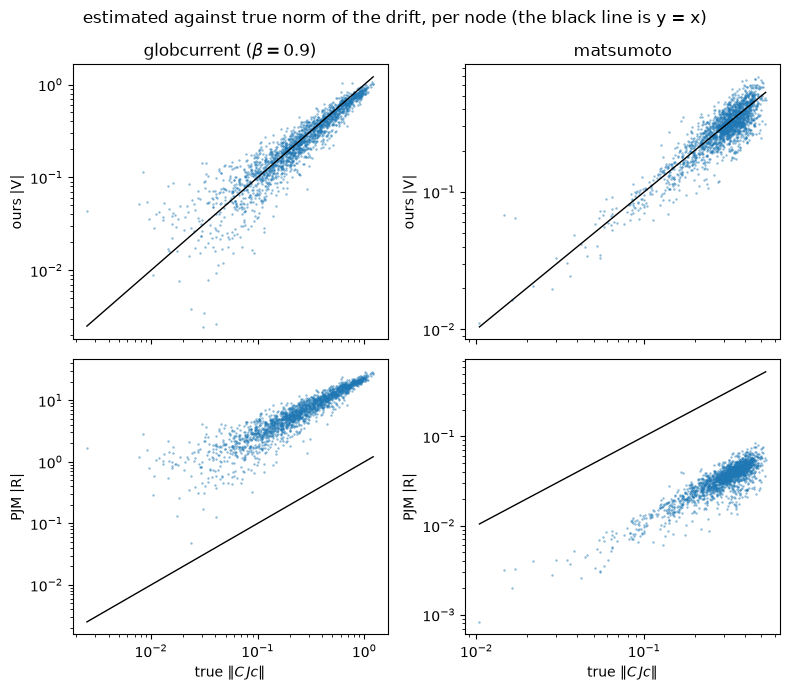

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7), sharex="col")
for column, key in enumerate([("globcurrent", 0.9), ("matsumoto", None)]):
    s = states[key]
    e = estimate(s)
    truth_norm = e["reference"].norm(dim=1).numpy()
    for row, (name, norm) in enumerate([("ours |V|", e["result"].drift.norm(dim=1)), ("PJM |R|", e["R"].norm(dim=1))]):
        ax = axes[row, column]
        ax.scatter(truth_norm, norm.numpy(), s=3, alpha=0.5, linewidths=0)
        low, high = np.nanmin(truth_norm), np.nanmax(truth_norm)
        ax.plot([low, high], [low, high], color="black", lw=1)  # calibrated: on this line
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylabel(name)
        if row == 1:
            ax.set_xlabel("true $\\|C\\,J c\\|$")
        if row == 0:
            ax.set_title(f"{key[0]}" + ("" if key[1] is None else f" ($\\beta={key[1]}$)"))
fig.suptitle("estimated against true norm of the drift, per node (the black line is y = x)")
fig.tight_layout()
plt.show()

## 3. Intrinsic strength

Reparametrise the same embedding by an anisotropic linear map, $Y\mapsto AY$ with $A=\mathrm{diag}(1,3)$, and estimate again with the same kernel. Median over the nodes of the ratio (reading after) / (reading before): a quantity that belongs to the data gives 1. The relative error of ours on $\|c\|^2_{g_{BL}}$ is the one of the other experiments (median over all the nodes).

In [7]:
A = torch.diag(torch.tensor([1.0, 3.0]))
rows = {}
for (d, b), s in states.items():
    before, after = estimate(s), estimate(s, A=A)
    ok = before["ok"] & after["ok"]
    rows[f"{d} {b}"] = {
        "ours ||c||^2 (intrinsic strength)": (after["result"].drift_norm_squared / before["result"].drift_norm_squared).median().item(),
        "ours |V|": (after["result"].drift.norm(dim=1) / before["result"].drift.norm(dim=1)).median().item(),
        "PJM |R|": (after["R"][ok].norm(dim=1) / before["R"][ok].norm(dim=1)).median().item(),
        "relerr ours before": before["relerr"],
        "relerr ours after": after["relerr"],
    }
pd.DataFrame(rows).T.round(2)

,ours ||c||^2 (intrinsic strength),ours |V|,PJM |R|,relerr ours before,relerr ours after
swiss_roll 0.3,1.0,1.02,1.02,0.13,0.13
swiss_roll 0.9,1.0,1.01,1.01,0.08,0.08
matsumoto None,1.0,2.39,2.34,0.15,0.15
globcurrent 0.5,1.0,1.67,1.68,0.25,0.26
globcurrent 0.9,1.0,1.67,1.67,0.21,0.21


## Reading the results (one sample of 2000 points per setting)

* **PJM does follow the relative magnitude.** Where the strength varies, the norm of $R$ is as correlated with the true one as ours is: Spearman 0.95 against 0.96 on GlobCurrent, 0.79 against 0.78 on Matsumoto ($\|V\|$; 0.87 for our strength $\|c\|^2$). In the figure its points make a band parallel to the line $y=x$. A statement that PJM ignores the magnitude of the drift is not what these data show.
* **PJM is not calibrated.** The norm of $R$ over the true norm goes from 0.04 to 25 across the settings and bandwidths, a factor 620 (it depends on the units of the embedding and on the bandwidth); ours stays between 0.80 and 1.36 without any constant. Dividing by $h$ and undoing the $\frac12$ of the formula brings PJM to the same range as ours (`2 PJM / h`, 0.83 to 1.39; `PJM / h` alone, 0.41 to 0.70). That scale is the one of the moment-Randers analysis (a step of a kernel built from a Randers distance moves by a multiple of $h$). The division by $\epsilon=h^2$ that the theory of the paper prescribes does not calibrate these kernels (`PJM / h^2`, 0.009 to 6.5, a factor 717, no better than $R$ itself): the model of the paper has a step that moves by $\epsilon\,r$, not by a multiple of $h$.
* **PJM has no intrinsic strength.** After a linear change of the coordinates of the same embedding, the norm of the drift changes by a factor 1.0 to 2.4 for PJM (and for our $\|V\|$, which is also a vector in coordinates), while our strength $\|c\|^2_{g_{BL}}$ is unchanged and keeps its error. It is the cometric $\Gamma$, estimated from the symmetric part of the kernel, that turns the drift into a strength that belongs to the data, bounded by the admissibility condition. PJM has no metric.
* **What is supported.** PJM gives the direction and a drift known up to a scale (relative magnitude), without the metric: no strength, no admissibility, no reconstruction of the Randers metric. A user who divides by $h$ obtains a calibrated drift, but with the scale law and the constant of our analysis, not with the ones of PJM; only ours also gives the intrinsic strength. The drift estimators are of the same kind (an antisymmetric operator applied to the coordinates), and they agree on direction and on relative magnitude: what is specific to the moment-Randers estimator is the scale law, the cometric, the admissibility condition and the reconstruction of the Randers metric, not a better estimate of the direction.
